# Processus de Poisson — Corrigé commenté

Chaque question est accompagnée du **raisonnement** (Markdown) puis du **code** qui l'illustre.
Les références « Poly » renvoient au polycopié du cours (`Poly.pdf`, section 4.3).

### Utilisation
* **Google Colab** : *Fichier → Importer un notebook*, puis *Exécution → Tout exécuter*. Aucun fichier de données ni
  installation n'est nécessaire (`numpy`, `matplotlib`, `scipy` sont préinstallés).
* **VS Code** (extension Jupyter) : ouvrir le notebook et exécuter tout.
* L'exécution complète prend environ 1 minute (les simulations Monte-Carlo de l'exercice 5 sont les plus longues).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(7)  # reproductibilité

In [2]:
def simuler_poisson(lmbda, T):
    t = 0
    sauts = []
    while t < T:
        t += np.random.exponential(1/lmbda)
        if t < T:
            sauts.append(t)
    return np.array(sauts)

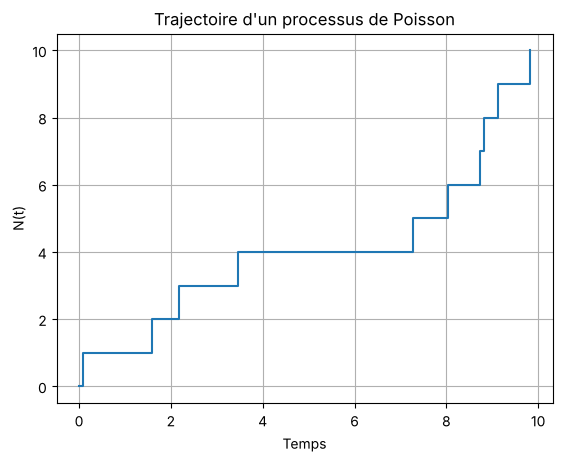

In [3]:
N = simuler_poisson(1, 10)
N = np.concatenate(([0], N))
t = np.arange(0, len(N))

# Tracé en escalier
plt.step(N, t, where='post')

plt.xlabel("Temps")
plt.ylabel("N(t)")
plt.title("Trajectoire d'un processus de Poisson")
plt.grid()

plt.show()

---
## Exercice 1. Estimation

### Question 1 — Estimateur de $\lambda$

**Raisonnement.** On observe la trajectoire sur $[0,T]$. On a $N_T\sim\mathcal P(\lambda T)$, donc
$\mathbb E[N_T]=\lambda T$. L'estimateur naturel (méthode des moments, c'est aussi l'estimateur du maximum de vraisemblance) est
$$\hat\lambda_T=\frac{N_T}{T}=\frac{\text{nombre de sauts observés}}{\text{durée d'observation}}.$$

*Justification MV* : la vraisemblance d'une trajectoire avec sauts $T_1<\dots<T_n$ dans $[0,T]$ est
$\prod_{i=1}^n\lambda e^{-\lambda(T_i-T_{i-1})}\times e^{-\lambda(T-T_n)}=\lambda^n e^{-\lambda T}$ ;
le log $n\log\lambda-\lambda T$ est maximal en $\lambda=n/T$.

In [4]:
lam, T = 2.0, 1000.0
sauts = simuler_poisson(lam, T)
lam_hat = len(sauts) / T
print(f"N_T = {len(sauts)} sauts sur [0, {T:.0f}]  ->  lambda_hat = N_T / T = {lam_hat:.4f}  (vrai lambda = {lam})")

N_T = 2035 sauts sur [0, 1000]  ->  lambda_hat = N_T / T = 2.0350  (vrai lambda = 2.0)


### Question 2 — Propriétés de $\hat\lambda_T$

* **Sans biais :** $\mathbb E[\hat\lambda_T]=\lambda T/T=\lambda$.
* **Variance :** $\operatorname{Var}(\hat\lambda_T)=\lambda T/T^2=\lambda/T\to0$.
* **Convergence (consistance forte) :** $\hat\lambda_T=N_T/T\xrightarrow{p.s.}\lambda$ (Poly : loi forte des grands nombres
  appliquée à $T_n/n\to1/\lambda$, puisque $N_{T_n}=n$).
* **Normalité asymptotique :** $N_T$ est la somme de $T$ accroissements i.i.d. $\mathcal P(\lambda)$ (pour $T$ entier), donc par le TCL
  $$\sqrt T\,(\hat\lambda_T-\lambda)\xrightarrow{\mathcal L}\mathcal N(0,\lambda).$$
  On en déduit l'intervalle de confiance asymptotique à 95 % : $\hat\lambda_T\pm1.96\sqrt{\hat\lambda_T/T}$.

**Illustrations :** (a) $T\mapsto\hat\lambda_T$ sur une même trajectoire (convergence p.s.) ;
(b) histogramme de $\sqrt T(\hat\lambda_T-\lambda)/\sqrt\lambda$ sur $M$ trajectoires indépendantes comparé à $\mathcal N(0,1)$ ;
(c) décroissance de l'écart-type empirique en $\sqrt{\lambda/T}$.

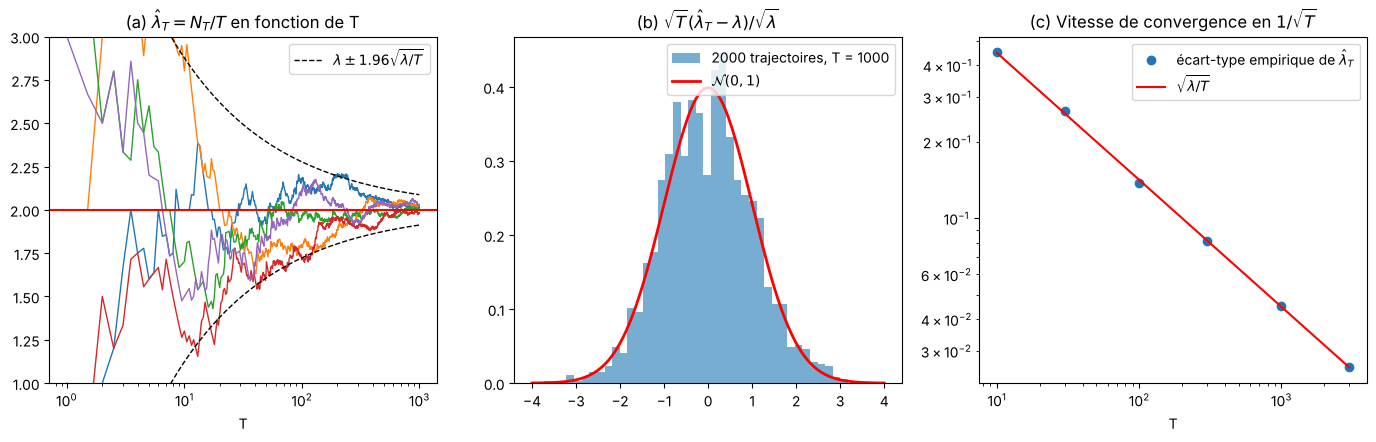

Moyenne des lambda_hat : 1.9998 (sans biais : 2.0)
Variance des lambda_hat : 0.00209 (théorie lambda/T = 0.00200)
Taux de couverture de l'IC asymptotique à 95% : 0.943
Test de Shapiro-Wilk sur Z : p-valeur = 0.569


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# (a) Convergence presque sûre sur quelques trajectoires
grille_T = np.linspace(1, T, 2000)
for _ in range(5):
    s = simuler_poisson(lam, T)
    ax[0].plot(grille_T, np.searchsorted(s, grille_T) / grille_T, lw=1)
ax[0].plot(grille_T, lam + 1.96*np.sqrt(lam/grille_T), 'k--', lw=1, label="$\\lambda \\pm 1.96\\sqrt{\\lambda/T}$")
ax[0].plot(grille_T, lam - 1.96*np.sqrt(lam/grille_T), 'k--', lw=1)
ax[0].axhline(lam, c='r'); ax[0].set_ylim(1, 3); ax[0].set_xscale('log')
ax[0].set_title("(a) $\\hat\\lambda_T = N_T/T$ en fonction de T"); ax[0].set_xlabel("T"); ax[0].legend()

# (b) Normalité asymptotique : M trajectoires de longueur T = 1000
# (on utilise que N_T ~ P(lambda T) ; on vérifie d'abord sur quelques trajectoires que c'est cohérent avec simuler_poisson)
M = 2000
NT = np.array([len(simuler_poisson(lam, T)) for _ in range(M)])
lam_hats = NT / T
Z = np.sqrt(T) * (lam_hats - lam) / np.sqrt(lam)
z = np.linspace(-4, 4, 200)
ax[1].hist(Z, bins=40, density=True, alpha=0.6, label=f"{M} trajectoires, T = {T:.0f}")
ax[1].plot(z, stats.norm.pdf(z), 'r', lw=2, label="$\\mathcal{N}(0,1)$")
ax[1].set_title("(b) $\\sqrt{T}(\\hat\\lambda_T-\\lambda)/\\sqrt{\\lambda}$"); ax[1].legend()

# (c) Écart-type en fonction de T
Ts = np.array([10, 30, 100, 300, 1000, 3000])
ect = [np.std(np.random.poisson(lam*Tk, size=5000) / Tk) for Tk in Ts]
ax[2].loglog(Ts, ect, 'o', label="écart-type empirique de $\\hat\\lambda_T$")
ax[2].loglog(Ts, np.sqrt(lam/Ts), 'r-', label="$\\sqrt{\\lambda/T}$")
ax[2].set_title("(c) Vitesse de convergence en $1/\\sqrt{T}$"); ax[2].set_xlabel("T"); ax[2].legend()
plt.show()

print(f"Moyenne des lambda_hat : {lam_hats.mean():.4f} (sans biais : {lam})")
print(f"Variance des lambda_hat : {lam_hats.var():.5f} (théorie lambda/T = {lam/T:.5f})")
couverture = np.mean(np.abs(lam_hats - lam) <= 1.96*np.sqrt(lam_hats/T))
print(f"Taux de couverture de l'IC asymptotique à 95% : {couverture:.3f}")
print(f"Test de Shapiro-Wilk sur Z : p-valeur = {stats.shapiro(Z[:500]).pvalue:.3f}")

Les trajectoires de $\hat\lambda_T$ se resserrent autour de $\lambda=2$ (convergence), restent dans le « tube » à
$\pm1.96\sqrt{\lambda/T}$, l'histogramme normalisé épouse la densité $\mathcal N(0,1)$ et l'écart-type décroît en
$1/\sqrt T$ : les propriétés théoriques sont bien illustrées.

### Question 3 — Loi du $k$-ème temps de saut ($k=5$, $\lambda=1$)

**Théorie.** $T_k=S_1+\dots+S_k$ est une somme de $k$ variables i.i.d. $\mathcal E(\lambda)$, donc
$T_k\sim\Gamma(k,\lambda)$ de densité $f(t)=\dfrac{\lambda^k t^{k-1}}{(k-1)!}e^{-\lambda t}$, de moyenne $k/\lambda=5$ et variance
$k/\lambda^2=5$.

**Méthode empirique (Monte-Carlo).** On simule $M$ trajectoires indépendantes du processus (sur un horizon assez long pour
avoir au moins 5 sauts), on relève pour chacune le 5ᵉ temps de saut, et on compare l'histogramme (estimation de la densité)
et la fonction de répartition empirique à la loi $\Gamma(5,1)$.

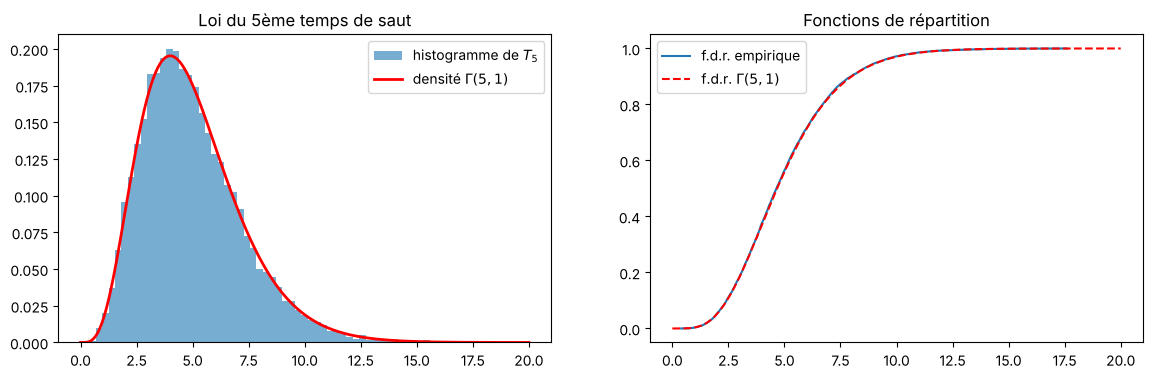

Moyenne empirique 4.979 (théorie 5.0),  variance empirique 4.983 (théorie 5.0)
Test KS contre Gamma(5,1) : p-valeur = 0.644


In [6]:
k, lam1, M = 5, 1.0, 10000
T5 = []
for _ in range(M):
    s = simuler_poisson(lam1, 30)          # horizon 30 : P(N_30 < 5) est astronomiquement petite
    T5.append(s[k-1])
T5 = np.array(T5)

t = np.linspace(0, 20, 400)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(T5, bins=60, density=True, alpha=0.6, label="histogramme de $T_5$")
ax[0].plot(t, stats.gamma.pdf(t, a=k, scale=1/lam1), 'r', lw=2, label="densité $\\Gamma(5,1)$")
ax[0].legend(); ax[0].set_title("Loi du 5ème temps de saut")
ax[1].plot(np.sort(T5), np.arange(1, M+1)/M, label="f.d.r. empirique")
ax[1].plot(t, stats.gamma.cdf(t, a=k, scale=1/lam1), 'r--', label="f.d.r. $\\Gamma(5,1)$")
ax[1].legend(); ax[1].set_title("Fonctions de répartition")
plt.show()
print(f"Moyenne empirique {T5.mean():.3f} (théorie {k/lam1}),  variance empirique {T5.var():.3f} (théorie {k/lam1**2})")
print(f"Test KS contre Gamma(5,1) : p-valeur = {stats.kstest(T5, 'gamma', args=(k, 0, 1/lam1)).pvalue:.3f}")

L'histogramme coïncide avec la densité $\Gamma(5,1)$, les moments empiriques sont proches de 5 et 5, et le test de
Kolmogorov-Smirnov ne rejette pas l'adéquation.

---
## Exercice 2. Processus de Poisson marqués (exercice 4.5 du Poly, $\lambda_A=2$, $\lambda_B=5$)

*Rappel de l'énoncé 4.5.* Les passages des lignes A et B sont des processus de Poisson indépendants d'intensités $\lambda_A$
et $\lambda_B$ (temps en heures). Un usager de la ligne B arrive au temps $t_0$.
1. Loi du nombre de bus pendant les deux premières heures ?
2. Un bus approche : probabilité qu'il soit de la ligne B ?
3. Probabilité que les deux premiers bus soient de la ligne A ?
4. Temps d'attente moyen d'un bus B sachant que le premier bus est de la ligne A ?

### Résolution théorique

Par absence de mémoire, après $t_0$ tout se passe comme si les deux processus démarraient en $t_0$ : on prend $t_0=0$.
Notons $\lambda=\lambda_A+\lambda_B=7$.

1. **Superposition (Poly, prop. 4.4)** : $N=N^A+N^B$ est un processus de Poisson d'intensité $\lambda=7$. Le nombre de bus en
   2 heures suit donc $\mathcal P(2\lambda)=\mathcal P(14)$ : $\mathbb P(N_2=k)=e^{-14}\frac{14^k}{k!}$.
2. **Compétition d'exponentielles** : le premier bus A arrive en $E_A\sim\mathcal E(\lambda_A)$, le premier B en
   $E_B\sim\mathcal E(\lambda_B)$, indépendants.
   $$\mathbb P(E_B<E_A)=\int_0^\infty\lambda_Be^{-\lambda_Bt}e^{-\lambda_At}\,dt=\frac{\lambda_B}{\lambda_A+\lambda_B}=\frac57\approx0.714.$$
   (De façon équivalente, par la prop. 4.5, chaque bus du processus superposé est de type B avec proba $p_B=\lambda_B/\lambda$, indépendamment.)
3. Les marques des bus successifs sont i.i.d. (A avec proba $2/7$) : $\mathbb P(\text{AA})=\left(\frac{\lambda_A}{\lambda}\right)^2=\frac4{49}\approx0.0816$.
4. Soit $W=E_B$ le temps d'attente d'un bus B. On cherche $\mathbb E[W\mid E_A<E_B]$. Sur cet événement,
   $W=\min(E_A,E_B)+(W-\min(E_A,E_B))$ :
   * $\min(E_A,E_B)\sim\mathcal E(\lambda)$ et est **indépendant** de l'événement $\{E_A<E_B\}$, donc d'espérance conditionnelle $1/\lambda$ ;
   * après le passage du bus A, par absence de mémoire, l'attente restante du bus B est $\mathcal E(\lambda_B)$, d'espérance $1/\lambda_B$.

   $$\mathbb E[W\mid E_A<E_B]=\frac1{\lambda_A+\lambda_B}+\frac1{\lambda_B}=\frac17+\frac15=\frac{12}{35}\text{ h}\approx 20.6\text{ min}.$$
   À comparer avec l'attente moyenne non conditionnelle $1/\lambda_B=12$ min : savoir que le premier bus est un A
   allonge l'attente.

### Vérification par Monte-Carlo
On simule les deux processus indépendants sur $[0,H]$ ($H=3\,$h, largement suffisant : la probabilité de ne voir aucun bus B en 3h est $e^{-15}$), on les fusionne en gardant la marque
de chaque bus, puis on estime chaque quantité par une moyenne empirique sur $M$ répétitions.

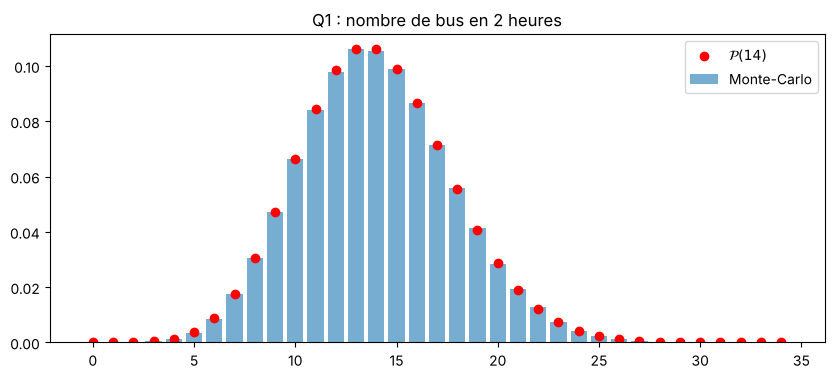

Q1 : moyenne 14.006, variance 14.025  (théorie : 14 et 14)
Q2 : P(premier bus = B)  MC = 0.7144 ± 0.0028   théorie 5/7  = 0.7143
Q3 : P(deux premiers A)  MC = 0.0826 ± 0.0017   théorie 4/49 = 0.0816
Q4 : E[attente B | 1er bus A] MC = 0.3443 ± 0.0029 h = 20.7 min   théorie 12/35 = 0.3429 h = 20.6 min
     (pour comparaison, E[attente B] sans condition : MC = 0.2000 h, théorie 1/5 = 0.2 h)


In [7]:
lamA, lamB = 2.0, 5.0
lamT = lamA + lamB
M, H = 100000, 3.0

nb2h = np.empty(M, dtype=int)
premier_B = np.empty(M, dtype=bool)
deux_A = np.empty(M, dtype=bool)
attente_B = np.empty(M)

for i in range(M):
    sA, sB = simuler_poisson(lamA, H), simuler_poisson(lamB, H)
    temps = np.concatenate((sA, sB))
    marques = np.concatenate((np.zeros(len(sA), bool), np.ones(len(sB), bool)))   # True = ligne B
    ordre = np.argsort(temps)
    marques = marques[ordre]
    nb2h[i] = np.sum(temps <= 2)
    premier_B[i] = marques[0]
    deux_A[i] = (not marques[0]) and (not marques[1])
    attente_B[i] = sB[0]

# Q1
k = np.arange(0, 35)
freq = np.bincount(nb2h, minlength=35)[:35] / M
plt.figure(figsize=(10, 4))
plt.bar(k, freq, alpha=0.6, label="Monte-Carlo")
plt.plot(k, stats.poisson.pmf(k, 2*lamT), 'ro', label="$\\mathcal{P}(14)$")
plt.title("Q1 : nombre de bus en 2 heures"); plt.legend(); plt.show()
print(f"Q1 : moyenne {nb2h.mean():.3f}, variance {nb2h.var():.3f}  (théorie : 14 et 14)")

# Q2 - Q4 avec intervalles de confiance à 95%
def ic(x):
    return x.mean(), 1.96 * x.std() / np.sqrt(len(x))

m, e = ic(premier_B.astype(float))
print(f"Q2 : P(premier bus = B)  MC = {m:.4f} ± {e:.4f}   théorie 5/7  = {lamB/lamT:.4f}")
m, e = ic(deux_A.astype(float))
print(f"Q3 : P(deux premiers A)  MC = {m:.4f} ± {e:.4f}   théorie 4/49 = {(lamA/lamT)**2:.4f}")
m, e = ic(attente_B[~premier_B])
print(f"Q4 : E[attente B | 1er bus A] MC = {m:.4f} ± {e:.4f} h = {60*m:.1f} min   "
      f"théorie 12/35 = {1/lamT + 1/lamB:.4f} h = {60*(1/lamT + 1/lamB):.1f} min")
print(f"     (pour comparaison, E[attente B] sans condition : MC = {attente_B.mean():.4f} h, théorie 1/5 = 0.2 h)")

Les estimations Monte-Carlo sont toutes compatibles avec les valeurs théoriques (elles sont dans les intervalles de confiance
à 95 %).

---
## Exercice 3. Processus de Poisson non-homogène, $\lambda(t)=2+\sin t$

### Question 1 — Méthode de simulation : l'amincissement (*thinning*, Lewis–Shedler)

**Idée.** $\lambda(t)\le\lambda_{\max}=3$ pour tout $t$. On simule un processus de Poisson **homogène** d'intensité
$\lambda_{\max}$, puis on conserve chaque point $T_i$ indépendamment avec probabilité $\lambda(T_i)/\lambda_{\max}$.

**Justification.** C'est la version « marquée » de la prop. 4.5 avec une probabilité de marquage dépendant du temps :
le nombre de points conservés dans un petit intervalle $[t,t+dt]$ vaut 1 avec probabilité
$\lambda_{\max}dt\times\lambda(t)/\lambda_{\max}=\lambda(t)dt$, et les accroissements restent indépendants. Le processus obtenu
est donc un processus de Poisson d'intensité $\lambda(t)$, avec $N_t\sim\mathcal P(\Lambda(t))$,
$\Lambda(t)=\int_0^t\lambda(s)ds=2t+1-\cos t$.

*(Autre méthode possible : inversion du temps, $T_i=\Lambda^{-1}(\Gamma_i)$ où $(\Gamma_i)$ est un Poisson homogène d'intensité 1.)*

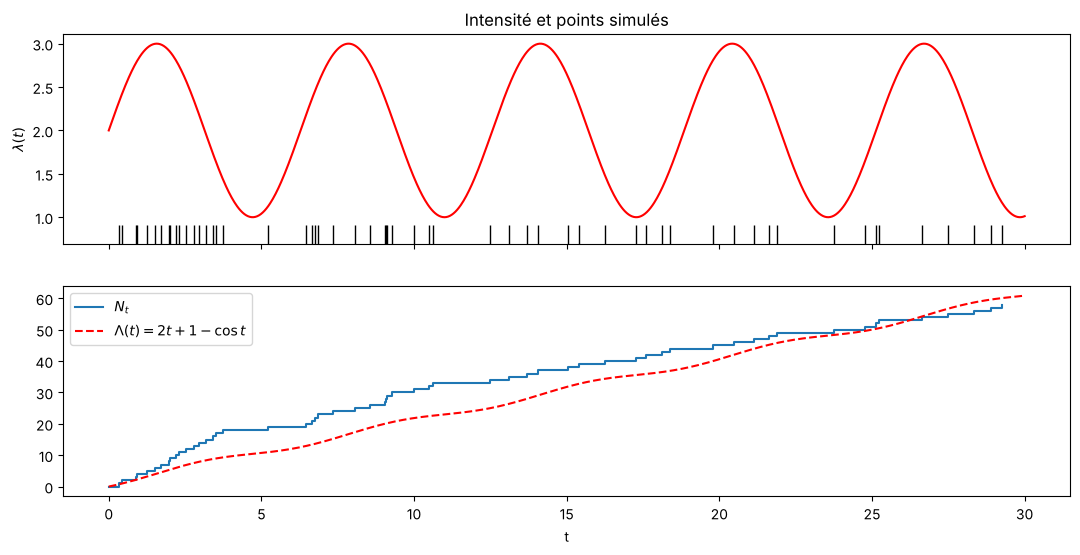

N_T = 58,  Lambda(T) = 60.85


In [8]:
def intensite(t):
    return 2 + np.sin(t)

def poisson_inhomogene(lmbda_fn, lmbda_max, T):
    candidats = simuler_poisson(lmbda_max, T)
    garde = np.random.rand(len(candidats)) < lmbda_fn(candidats) / lmbda_max
    return candidats[garde]

T3 = 30.0
s = poisson_inhomogene(intensite, 3.0, T3)
tt = np.linspace(0, T3, 1000)

fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].plot(tt, intensite(tt), 'r'); ax[0].plot(s, np.full_like(s, 0.8), '|', ms=15, c='k')
ax[0].set_ylabel("$\\lambda(t)$"); ax[0].set_title("Intensité et points simulés")
ax[1].step(np.concatenate(([0], s)), np.arange(len(s) + 1), where='post', label="$N_t$")
ax[1].plot(tt, 2*tt + 1 - np.cos(tt), 'r--', label="$\\Lambda(t)=2t+1-\\cos t$")
ax[1].set_xlabel("t"); ax[1].legend()
plt.show()
print(f"N_T = {len(s)},  Lambda(T) = {2*T3 + 1 - np.cos(T3):.2f}")

On voit des grappes de points là où $\sin t$ est proche de 1 et des zones plus clairsemées là où il vaut $-1$.

### Question 2 — Estimation empirique de l'intensité

**Raisonnement.** Pour un petit intervalle $I=[t,t+h[$, $\mathbb E[N(I)]=\int_I\lambda(s)ds\approx\lambda(t)h$.
Avec $M$ trajectoires indépendantes, la loi des grands nombres donne l'estimateur **histogramme** :
$$\hat\lambda(t)=\frac{1}{M\,h}\sum_{m=1}^M N^{(m)}([t,t+h[).$$
Il est sans biais pour la moyenne de $\lambda$ sur la case, et sa variance $\approx\lambda(t)/(Mh)$ : on a un compromis
biais/variance sur $h$ (petit $h$ ⇒ moins de biais mais plus de bruit). On peut aussi lisser avec un noyau
(estimateur à noyau : $\hat\lambda(t)=\frac1M\sum_{m}\sum_i K_h(t-T_i^{(m)})$).

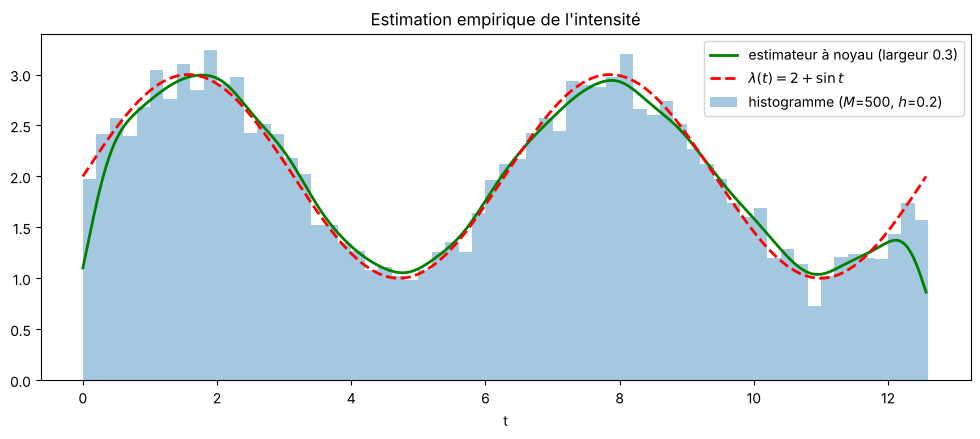

Erreur absolue moyenne (histogramme) : 0.113


In [9]:
M3, T3 = 500, 4*np.pi
tous = np.concatenate([poisson_inhomogene(intensite, 3.0, T3) for _ in range(M3)])

h = 0.2
bords = np.arange(0, T3 + h, h)
compte, _ = np.histogram(tous, bins=bords)
centres = (bords[:-1] + bords[1:]) / 2
lam_hist = compte / (M3 * h)

# Estimateur à noyau gaussien (largeur 0.3)
bw = 0.3
tt = np.linspace(0, T3, 400)
lam_noyau = np.array([np.sum(stats.norm.pdf((t - tous) / bw)) / (bw * M3) for t in tt])

plt.figure(figsize=(12, 4.5))
plt.bar(centres, lam_hist, width=h, alpha=0.4, label=f"histogramme ($M$={M3}, $h$={h})")
plt.plot(tt, lam_noyau, 'g', lw=2, label=f"estimateur à noyau (largeur {bw})")
plt.plot(tt, intensite(tt), 'r--', lw=2, label="$\\lambda(t) = 2+\\sin t$")
plt.xlabel("t"); plt.legend(); plt.title("Estimation empirique de l'intensité")
plt.show()

mask = (centres > 0.5) & (centres < T3 - 0.5)
print(f"Erreur absolue moyenne (histogramme) : {np.mean(np.abs(lam_hist - intensite(centres))):.3f}")

L'intensité estimée reproduit bien la sinusoïde $2+\sin t$. (L'estimateur à noyau sous-estime légèrement près de $0$ et
de $T$ — effet de bord, car il « voit » une zone vide en dehors de $[0,T]$.)

---
## Exercice 4. Processus ponctuel de Poisson dans $\mathbb R^2$ ($\lambda=1$, carré $[0;100]^2$)

**Méthode.** Sur $A=[0,100]^2$, vol$(A)=10^4$.
1. On tire le nombre de points $N_A\sim\mathcal P(\lambda\,\text{vol}(A))=\mathcal P(10\,000)$.
2. Conditionnellement à $N_A=n$, on place $n$ points **i.i.d. uniformes** dans le carré.

**Justification.** C'est la version spatiale de la propriété « conditionnellement à $N_t=n$, les sauts sont uniformes »
(Poly). Pour un borélien $B\subset A$, conditionnellement à $N_A=n$, $N_B\sim\mathcal B(n,|B|/|A|)$ ; en dé-conditionnant
(même calcul que la prop. 4.5, amincissement d'une loi de Poisson) on obtient
$N_B\sim\mathcal P(\lambda|B|)$, et de même $N_B$, $N_{A\setminus B}$ sont indépendants : c'est bien un processus de Poisson
d'intensité $\lambda$ restreint à $A$.

**Vérification.** On découpe le carré en $10\times10$ cases de surface 100 : les comptages doivent être i.i.d. $\mathcal P(100)$.

Nombre de points simulés : 9990 (espérance 10000)


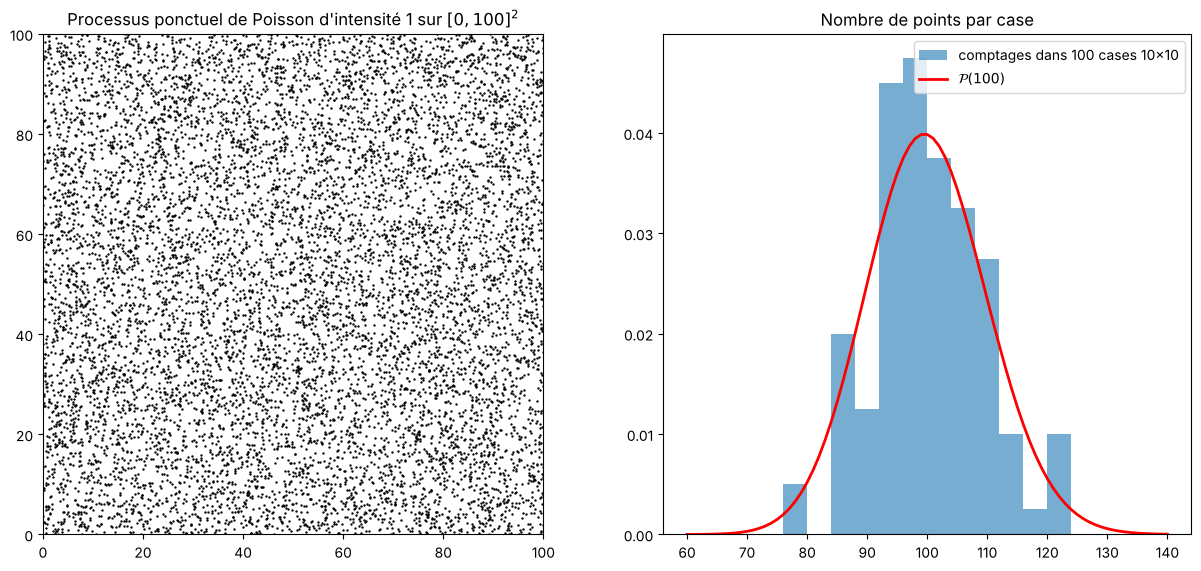

Comptages par case : moyenne 99.9, variance 85.3 (théorie : 100 et 100)


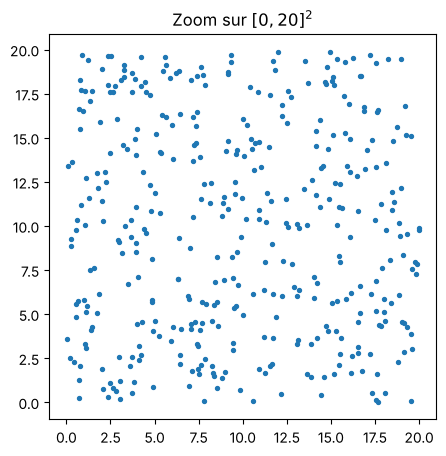

In [10]:
lam2d, L = 1.0, 100.0
n_pts = np.random.poisson(lam2d * L**2)
pts = np.random.uniform(0, L, size=(n_pts, 2))
print(f"Nombre de points simulés : {n_pts} (espérance {lam2d*L**2:.0f})")

fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
ax[0].scatter(pts[:, 0], pts[:, 1], s=0.5, c='k')
ax[0].set_aspect('equal'); ax[0].set_xlim(0, L); ax[0].set_ylim(0, L)
ax[0].set_title("Processus ponctuel de Poisson d'intensité 1 sur $[0,100]^2$")

comptes, _, _ = np.histogram2d(pts[:, 0], pts[:, 1], bins=10, range=[[0, L], [0, L]])
comptes = comptes.ravel()
k = np.arange(60, 141)
ax[1].hist(comptes, bins=np.arange(60, 142, 4), density=True, alpha=0.6, label="comptages dans 100 cases 10x10")
ax[1].plot(k, stats.poisson.pmf(k, 100), 'r', lw=2, label="$\\mathcal{P}(100)$")
ax[1].legend(); ax[1].set_title("Nombre de points par case")
plt.show()
print(f"Comptages par case : moyenne {comptes.mean():.1f}, variance {comptes.var():.1f} (théorie : 100 et 100)")

# Zoom pour visualiser l'absence de structure
plt.figure(figsize=(5, 5))
z = (pts[:, 0] < 20) & (pts[:, 1] < 20)
plt.scatter(pts[z, 0], pts[z, 1], s=8); plt.gca().set_aspect('equal')
plt.title("Zoom sur $[0,20]^2$"); plt.show()

Moyenne et variance des comptages sont toutes deux proches de 100 (moyenne = variance, signature de la loi de Poisson ;
avec seulement 100 cases, la variance empirique fluctue d'environ $\pm 15$ autour de 100) :
la simulation est conforme. Visuellement les points sont « complètement aléatoires » : pas de régularité, mais des amas et
des trous apparaissent naturellement.

---
## Exercice 5. Simulation de files d'attente (contrôle des passeports)

### Question 1 — Modèle

* **Arrivées** : processus de Poisson homogène d'intensité $\lambda=40$ personnes/heure sur $[8\text{h},17\text{h}]$
  (9 heures ; $\approx360$ personnes en moyenne). Personne n'arrive après 17h.
* **Services** : durées i.i.d. $\mathcal U([1,5])$ minutes, indépendantes des arrivées (moyenne 3 min).
* **Guichets** : $c=2$ serveurs, file unique, discipline « premier arrivé, premier servi » : chaque voyageur, dans l'ordre
  d'arrivée, va au premier guichet qui se libère.

Si $a_i$ est l'heure d'arrivée du $i$-ème voyageur et $f_j$ l'instant où le guichet $j$ se libère :
$$\text{début}_i=\max\bigl(a_i,\ \min_j f_j\bigr),\qquad \text{fin}_i=\text{début}_i+S_i,\quad f_{j^*}\leftarrow\text{fin}_i .$$
L'heure de fin des contrôles est $\max_i \text{fin}_i$.

**Remarque importante (charge du système).** Le taux d'arrivée est $\lambda=40/\text{h}$ et la capacité de deux guichets est
$2\times\frac{60}{3}=40/\text{h}$ : le facteur de charge vaut $\rho=\frac{\lambda\,\mathbb E[S]}{c}=1$.
Le système est à la limite de la saturation : la file se comporte comme une marche aléatoire sans dérive (réfléchie en 0),
sa longueur croît typiquement en $\sqrt t$. Il restera donc souvent du monde à 17h, et la question est de savoir si ce
retard est résorbé avant 18h.

Le temps est mesuré en minutes à partir de 8h (17h = 540, 18h = 600).

379 voyageurs, dernier contrôle terminé à 17h29
Attente moyenne : 11.1 min, attente max : 29.8 min


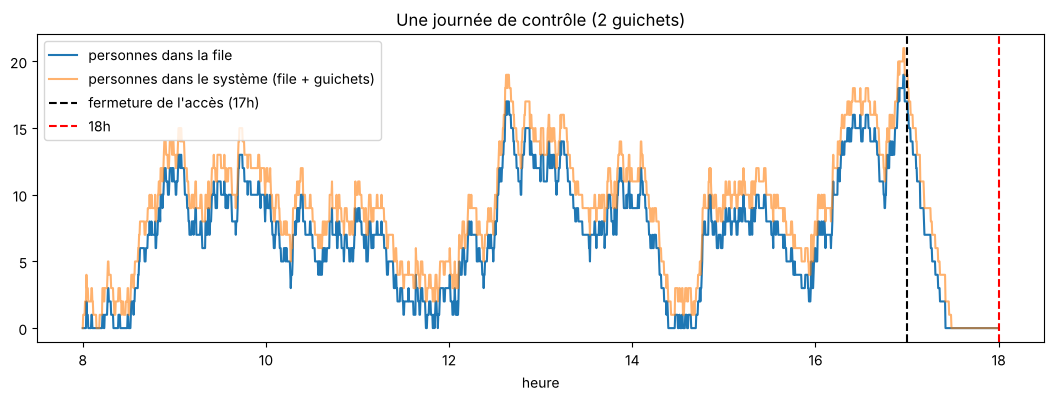

In [11]:
LAM_MIN = 40 / 60        # arrivées par minute
OUVERTURE, FERMETURE, LIMITE = 0.0, 540.0, 600.0   # 8h, 17h, 18h en minutes depuis 8h

def simuler_controle(ouvertures_guichets=(0.0, 0.0), detail=False):
    # ouvertures_guichets : instant (min depuis 8h) d'ouverture de chaque guichet
    arrivees = simuler_poisson(LAM_MIN, FERMETURE)
    services = np.random.uniform(1, 5, size=len(arrivees))
    libre = [float(o) for o in ouvertures_guichets]
    debut = np.empty(len(arrivees)); fin = np.empty(len(arrivees))
    for i, (a, s) in enumerate(zip(arrivees.tolist(), services.tolist())):
        j = libre.index(min(libre))       # guichet qui se libère le premier
        d = a if a > libre[j] else libre[j]
        debut[i] = d
        fin[i] = d + s
        libre[j] = d + s
    fin_controles = fin.max() if len(fin) else 0.0
    if detail:
        return arrivees, debut, fin
    return fin_controles

def hm(minutes):
    m = int(round(8*60 + minutes))
    return f"{m // 60}h{m % 60:02d}"

# Une journée simulée
arr, deb, fin = simuler_controle(detail=True)
print(f"{len(arr)} voyageurs, dernier contrôle terminé à {hm(fin.max())}")
print(f"Attente moyenne : {np.mean(deb - arr):.1f} min, attente max : {np.max(deb - arr):.1f} min")

grille = np.linspace(0, max(fin.max(), 600), 2000)
dans_systeme = np.searchsorted(np.sort(arr), grille, side='right') - np.searchsorted(np.sort(fin), grille, side='right')
en_attente = np.searchsorted(np.sort(arr), grille, side='right') - np.searchsorted(np.sort(deb), grille, side='right')
plt.figure(figsize=(13, 4))
plt.plot(8 + grille/60, en_attente, label="personnes dans la file")
plt.plot(8 + grille/60, dans_systeme, alpha=0.6, label="personnes dans le système (file + guichets)")
plt.axvline(17, c='k', ls='--', label="fermeture de l'accès (17h)")
plt.axvline(18, c='r', ls='--', label="18h")
plt.xlabel("heure"); plt.legend(); plt.title("Une journée de contrôle (2 guichets)")
plt.show()

### Question 2 — Probabilité que les contrôles ne soient pas terminés à 18h

**Estimateur Monte-Carlo.** On répète $M$ journées indépendantes et on calcule
$\hat p=\frac1M\sum_{m=1}^M\mathbf 1\{\text{fin}^{(m)}>18\text{h}\}$, avec l'intervalle de confiance à 95 %
$\hat p\pm1.96\sqrt{\hat p(1-\hat p)/M}$ (TCL).

P(contrôles non terminés à 18h) ≈ 0.0566  (IC 95% : [0.0502 ; 0.0630])


Heure de fin médiane : 17h21,  quantile 90% : 17h52


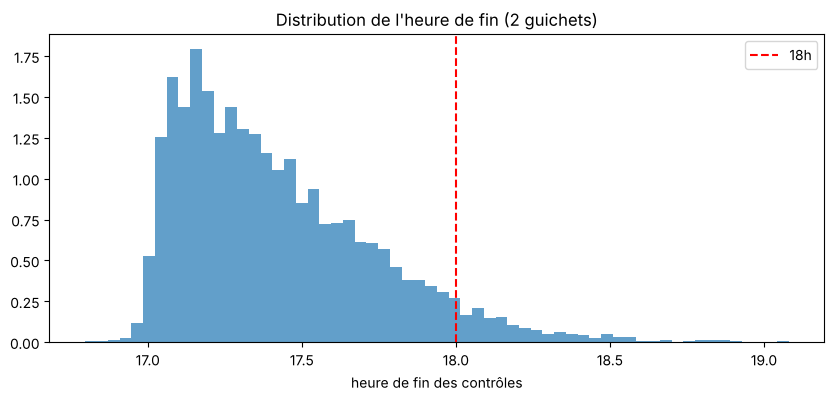

In [12]:
M5 = 5000
fins = np.array([simuler_controle() for _ in range(M5)])
p = np.mean(fins > LIMITE)
e = 1.96*np.sqrt(p*(1-p)/M5)
print(f"P(contrôles non terminés à 18h) ≈ {p:.4f}  (IC 95% : [{p-e:.4f} ; {p+e:.4f}])")
print(f"Heure de fin médiane : {hm(np.median(fins))},  quantile 90% : {hm(np.quantile(fins, 0.9))}")

plt.figure(figsize=(10, 4))
plt.hist(8 + fins/60, bins=60, density=True, alpha=0.7)
plt.axvline(18, c='r', ls='--', label="18h")
plt.xlabel("heure de fin des contrôles"); plt.legend()
plt.title("Distribution de l'heure de fin (2 guichets)"); plt.show()

### Question 3 — Heure d'ouverture au plus tard d'un troisième guichet

**Démarche.** Pour chaque heure d'ouverture candidate $s$ du 3ᵉ guichet (de 8h à 18h par pas de 15 minutes), on estime par
Monte-Carlo $q(s)=\mathbb P(\text{fin}\le18\text{h})$ avec trois guichets ouverts respectivement en $0,0,s$.
$q$ est décroissante en $s$ (ouvrir plus tard ne peut qu'aider moins). On retient la plus grande heure $s$ telle que
$q(s)\ge0.9$.

Pour une comparaison plus précise entre les valeurs de $s$, on utilise des **nombres aléatoires communs** : la même graine pour
chaque $s$, donc les mêmes journées (arrivées et durées de service) sont rejouées ; seule l'heure d'ouverture change. Cela
réduit fortement la variance de la comparaison et garantit une courbe monotone.

Comme une estimation Monte-Carlo est entachée d'erreur, on recommande de garder une petite **marge de sécurité** : retenir
l'heure où la borne inférieure de l'IC à 95 % reste au-dessus de 0.9.

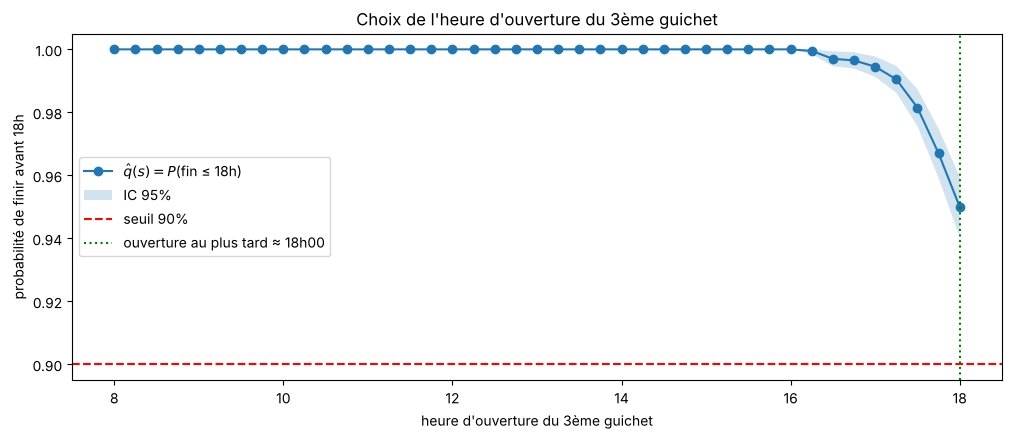

ouverture à 8h00 : P(fin ≤ 18h) ≈ 1.000
ouverture à 9h00 : P(fin ≤ 18h) ≈ 1.000
ouverture à 10h00 : P(fin ≤ 18h) ≈ 1.000
ouverture à 11h00 : P(fin ≤ 18h) ≈ 1.000
ouverture à 12h00 : P(fin ≤ 18h) ≈ 1.000
ouverture à 13h00 : P(fin ≤ 18h) ≈ 1.000
ouverture à 14h00 : P(fin ≤ 18h) ≈ 1.000
ouverture à 15h00 : P(fin ≤ 18h) ≈ 1.000
ouverture à 16h00 : P(fin ≤ 18h) ≈ 1.000
ouverture à 17h00 : P(fin ≤ 18h) ≈ 0.995
ouverture à 18h00 : P(fin ≤ 18h) ≈ 0.950

Seuil 90% : ouverture au plus tard ≈ 18h00 (= jamais besoin : 2 guichets suffisent)   | avec marge (borne basse IC) : 18h00
Seuil 95% : ouverture au plus tard ≈ 18h00 (= jamais besoin : 2 guichets suffisent)   | avec marge (borne basse IC) : 17h45
Seuil 99% : ouverture au plus tard ≈ 17h15   | avec marge (borne basse IC) : 17h00


In [13]:
M_q3 = 2000
candidats = np.arange(0, 601, 15)       # minutes depuis 8h : 8h00, 8h15, ..., 18h00
q, q_bas = [], []
for s in candidats:
    np.random.seed(12345)               # nombres aléatoires communs
    f = np.array([simuler_controle((0.0, 0.0, float(s))) for _ in range(M_q3)])
    pq = np.mean(f <= LIMITE)
    q.append(pq); q_bas.append(pq - 1.96*np.sqrt(pq*(1-pq)/M_q3))
q, q_bas = np.array(q), np.array(q_bas)

def plus_tard(seuil, proba):
    ok = candidats[proba >= seuil]
    return ok.max() if len(ok) else None

s_star = plus_tard(0.9, q)

plt.figure(figsize=(12, 4.5))
plt.plot(8 + candidats/60, q, 'o-', label="$\\hat q(s) = P$(fin ≤ 18h)")
plt.fill_between(8 + candidats/60, q_bas, np.minimum(1, 2*q - q_bas), alpha=0.2, label="IC 95%")
plt.axhline(0.9, c='r', ls='--', label="seuil 90%")
if s_star is not None:
    plt.axvline(8 + s_star/60, c='g', ls=':', label=f"ouverture au plus tard ≈ {hm(s_star)}")
plt.xlabel("heure d'ouverture du 3ème guichet"); plt.ylabel("probabilité de finir avant 18h")
plt.legend(); plt.title("Choix de l'heure d'ouverture du 3ème guichet"); plt.show()

for s, pq in zip(candidats[::4], q[::4]):
    print(f"ouverture à {hm(s)} : P(fin ≤ 18h) ≈ {pq:.3f}")
print()
for seuil in [0.90, 0.95, 0.99]:
    s1, s2 = plus_tard(seuil, q), plus_tard(seuil, q_bas)
    txt1 = hm(s1) if s1 is not None else "impossible"
    txt2 = hm(s2) if s2 is not None else "impossible"
    if s1 == 600:
        txt1 += " (= jamais besoin : 2 guichets suffisent)"
    print(f"Seuil {seuil:.0%} : ouverture au plus tard ≈ {txt1}   | avec marge (borne basse IC) : {txt2}")

**Conclusion et proposition.**

* D'après la question 2, avec seulement deux guichets, $\mathbb P(\text{fin}\le18\text{h})\approx 1-0.057\approx0.94>0.9$.
  **Le critère de 90 % est donc déjà satisfait sans troisième guichet** : la courbe $\hat q(s)$ reste au-dessus de 0.9 même
  pour une ouverture à 18h (ce qui revient à ne jamais l'ouvrir). La réponse rigoureuse est : *il n'est pas nécessaire d'ouvrir
  un troisième guichet ; n'importe quelle heure convient, y compris « jamais ».*
  Par prudence (la marge 0.94 vs 0.90 dépend des hypothèses du modèle, notamment de $\rho=1$ qui rend le système très
  sensible : une affluence de 42/h au lieu de 40/h suffit à dégrader nettement le résultat), on peut néanmoins prévoir
  un agent en renfort vers 17h si la file est longue.
* Si l'on exige un niveau plus élevé, la même méthode donne l'heure limite : le tableau ci-dessus indique par exemple
  l'heure d'ouverture au plus tard pour 95 % et 99 %. L'intuition : avec $\rho=1$ la file accumulée dans la journée est
  résorbée lentement par 2 guichets ; un 3ᵉ guichet porte la capacité à 60 personnes/heure et vide le retard trois fois plus vite.

Pour affiner, on peut réduire le pas de la grille (5 min) autour des valeurs trouvées et augmenter $M$.